<a href="https://colab.research.google.com/github/Philip5717021/Philip5717021-DataScience-GenAI-Submissions/blob/main/Copy_of_titanic_data_set.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from google.colab import files
upload = files.upload()

Saving titanic (1).csv to titanic (1).csv


In [ ]:
import io

# Load the dataset using the uploaded file name
df = pd.read_csv('titanic (1).csv')
display(df.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
df.info()

Dataset Shape: 891 rows, 12 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
missing_values = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage (%)': missing_percentage
})

display(missing_df[missing_df['Missing Values'] > 0])

,Missing Values,Percentage (%)
Age,177,19.865320
Cabin,687,77.104377
Embarked,2,0.224467


In [ ]:
display(df.describe())

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
# Group by 'Sex' and calculate the average of 'Survived'
survival_by_gender = df.groupby('Sex')['Survived'].mean().reset_index()

# Rename columns for clarity
survival_by_gender.columns = ['Gender', 'Survival Rate']

# Convert the rate to a percentage format for easy reading
survival_by_gender['Survival Percentage (%)'] = survival_by_gender['Survival Rate'] * 100

# Display the resulting table
display(survival_by_gender[['Gender', 'Survival Percentage (%)']])

,Gender,Survival Percentage (%)
0,female,74.203822
1,male,18.890815


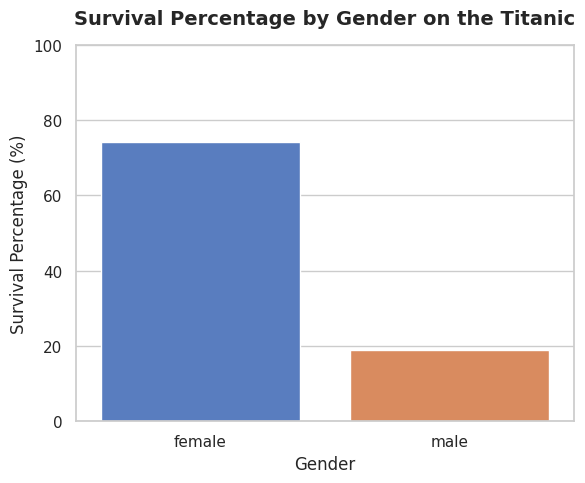

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the aesthetic style of the plot
sns.set_theme(style="whitegrid")

# Create the bar chart
plt.figure(figsize=(6, 5))
sns.barplot(
    x='Gender',
    y='Survival Percentage (%)',
    data=survival_by_gender,
    palette='muted',
    hue='Gender',
    legend=False
)

# Add titles and labels
plt.title('Survival Percentage by Gender on the Titanic', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Gender', fontsize=12)
plt.ylabel('Survival Percentage (%)', fontsize=12)
plt.ylim(0, 100)

# Display the plot
plt.tight_layout()
plt.show()

It is evident that females had a much higher survival rate compared to males.